<a href="https://colab.research.google.com/github/192524103simats-star/CSA4705/blob/main/UNIT_3_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=1000, n_features=10, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

for opt in ['sgd', 'rmsprop', 'adam']:
    model = Sequential([Dense(16, activation='relu', input_shape=(10,)),
                        Dense(1, activation='sigmoid')])
    model.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
    model.fit(X_train, y_train, epochs=10, verbose=0)
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    print(opt.upper(), 'Accuracy:', round(acc, 4), 'Loss:', round(loss, 4))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


SGD Accuracy: 0.83 Loss: 0.4444
RMSPROP Accuracy: 0.845 Loss: 0.36
ADAM Accuracy: 0.855 Loss: 0.427


In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

model = Sequential([Flatten(input_shape=(28, 28)),
                    Dense(128, activation='relu'),
                    Dense(64, activation='relu'),
                    Dense(10, activation='softmax')])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(x_train, y_train, epochs=5, validation_split=0.1)
print('Test accuracy:', model.evaluate(x_test, y_test)[1])

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9249 - loss: 0.2539 - val_accuracy: 0.9687 - val_loss: 0.1092
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9681 - loss: 0.1054 - val_accuracy: 0.9730 - val_loss: 0.1007
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9771 - loss: 0.0752 - val_accuracy: 0.9763 - val_loss: 0.0804
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9829 - loss: 0.0564 - val_accuracy: 0.9757 - val_loss: 0.0879
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9861 - loss: 0.0440 - val_accuracy: 0.9793 - val_loss: 0.0706
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9761 - loss: 0.0815
Test accuracy: 0.9761000275611877


In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=700, n_features=20, random_state=42)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

for use_dropout in [False, True]:
    layers = [Dense(128, activation='relu', input_shape=(20,))]
    if use_dropout: layers.append(Dropout(0.5))
    layers += [Dense(64, activation='relu'), Dense(1, activation='sigmoid')]
    model = Sequential(layers)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    h = model.fit(Xtr, ytr, epochs=15, validation_split=0.2, verbose=0)
    print('Dropout:', use_dropout,
          'Train accuracy:', round(h.history['accuracy'][-1], 4),
          'Validation accuracy:', round(h.history['val_accuracy'][-1], 4))

Dropout: False Train accuracy: 0.9464 Validation accuracy: 0.8571
Dropout: True Train accuracy: 0.8683 Validation accuracy: 0.8571


In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential, regularizers
from tensorflow.keras.layers import Dense
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=800, n_features=10, random_state=42)
for l2 in [0.0, 0.01]:
    model = Sequential([Dense(16, activation='relu', input_shape=(10,),
                              kernel_regularizer=regularizers.l2(l2)),
                        Dense(1, activation='sigmoid')])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    model.fit(X, y, epochs=10, verbose=0)
    weights = model.layers[0].get_weights()[0]
    print('L2:', l2, 'Accuracy:', round(model.evaluate(X, y, verbose=0)[1], 4),
          'Mean absolute weight:', round(abs(weights).mean(), 4))

L2: 0.0 Accuracy: 0.9162 Mean absolute weight: 0.253


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


L2: 0.01 Accuracy: 0.9087 Mean absolute weight: 0.1849


In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential, regularizers
from tensorflow.keras.layers import Dense
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=1000, n_features=20, random_state=42)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
for reg in [None, regularizers.l2(0.01)]:
    model = Sequential([Dense(32, activation='relu', input_shape=(20,), kernel_regularizer=reg),
                        Dense(1, activation='sigmoid')])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    model.fit(Xtr, ytr, epochs=15, verbose=0)
    print('Regularizer:', 'L2' if reg else 'None',
          'Train:', round(model.evaluate(Xtr, ytr, verbose=0)[1], 4),
          'Test:', round(model.evaluate(Xte, yte, verbose=0)[1], 4))

Regularizer: None Train: 0.8975 Test: 0.85
Regularizer: L2 Train: 0.8875 Test: 0.855


In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

(xtr, ytr), (xte, yte) = tf.keras.datasets.mnist.load_data()
xtr, xte = xtr[..., None] / 255.0, xte[..., None] / 255.0
model = Sequential([Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
                    MaxPooling2D(), Flatten(), Dense(64, activation='relu'),
                    Dense(10, activation='softmax')])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(xtr, ytr, epochs=3, validation_split=0.1)
print('Test accuracy:', model.evaluate(xte, yte)[1])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 33s 19ms/step - accuracy: 0.9463 - loss: 0.1838 - val_accuracy: 0.9807 - val_loss: 0.0723
Epoch 2/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 33s 19ms/step - accuracy: 0.9798 - loss: 0.0648 - val_accuracy: 0.9843 - val_loss: 0.0564
Epoch 3/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 34s 20ms/step - accuracy: 0.9859 - loss: 0.0454 - val_accuracy: 0.9835 - val_loss: 0.0589
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9805 - loss: 0.0582
Test accuracy: 0.9804999828338623


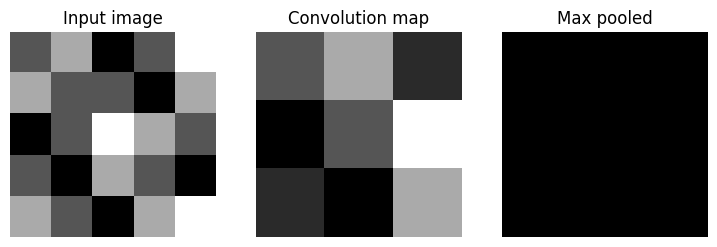

Feature map:
 [[-1.  1. -2.]
 [-3. -1.  3.]
 [-2. -3.  1.]] 
Pooled map:
 [[1.]]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate2d

img = np.array([[1,2,0,1,3], [2,1,1,0,2], [0,1,3,2,1],
                [1,0,2,1,0], [2,1,0,2,3]], dtype=float)
kernel = np.array([[1,0,-1], [1,0,-1], [1,0,-1]])
feature = correlate2d(img, kernel, mode='valid')
pooled = np.array([[feature[i:i+2, j:j+2].max()
                    for j in range(0, feature.shape[1]-1, 2)]
                   for i in range(0, feature.shape[0]-1, 2)])
plt.figure(figsize=(9,3))
for i, (a, title) in enumerate([(img,'Input image'),(feature,'Convolution map'),(pooled,'Max pooled')]):
    plt.subplot(1,3,i+1); plt.imshow(a, cmap='gray'); plt.title(title); plt.axis('off')
plt.show()
print('Feature map:\n', feature, '\nPooled map:\n', pooled)

In [ ]:
import numpy as np
from tensorflow.keras.layers import MaxPooling2D, AveragePooling2D

image = np.array([[[[1.],[3.],[2.],[4.]],
                   [[5.],[6.],[7.],[8.]],
                   [[2.],[4.],[1.],[3.]],
                   [[6.],[8.],[5.],[7.]]]])
print('Max pooling:\n', MaxPooling2D(pool_size=(2,2))(image).numpy().reshape(2,2))
print('Average pooling:\n', AveragePooling2D(pool_size=(2,2))(image).numpy().reshape(2,2))

Max pooling:
 [[6. 8.]
 [8. 7.]]
Average pooling:
 [[3.75 5.25]
 [5.   4.  ]]


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.Y4BE1J_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Dataset loaded successfully!
Epoch 1/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 253s 432ms/step - accuracy: 0.6987 - loss: 0.5693 - val_accuracy: 0.7603 - val_loss: 0.4886
Epoch 2/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 243s 418ms/step - accuracy: 0.7965 - loss: 0.4366 - val_accuracy: 0.7685 - val_loss: 0.4719
Epoch 3/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 247s 425ms/step - accuracy: 0.8427 - loss: 0.3554 - val_accuracy: 0.7511 - val_loss: 0.5122
Epoch 4/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 248s 426ms/step - accuracy: 0.8851 - loss: 0.2682 - val_accuracy: 0.7724 - val_loss: 0.5416
Epoch 5/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 260s 422ms/step - accuracy: 0.9139 - loss: 0.2138 - val_accuracy: 0.7631 - val_loss: 0.5932
146/146 ━━━━━━━━━━━━━━━━━━━━ 19s 130ms/step - accuracy: 0.7631 - loss: 0.5932
Test Accuracy: 0.7631126642227173
Test Loss: 0.5932022333145142


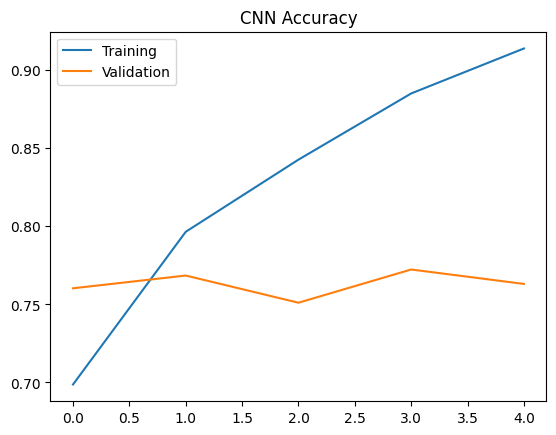

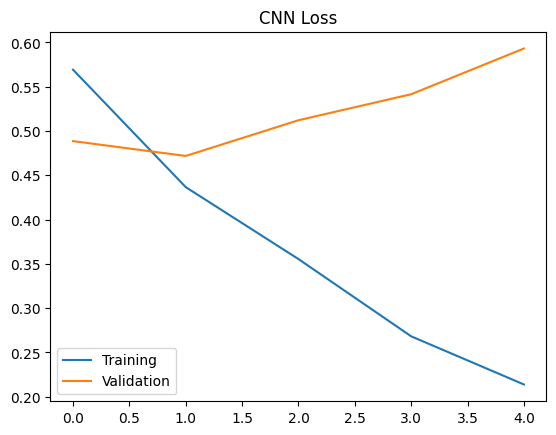

In [7]:
!pip install -q importlib-resources tensorflow-datasets
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

# Load dataset
(train, test), info = tfds.load(
    "cats_vs_dogs",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True,
    download=True
)

print("Dataset loaded successfully!")

# Preprocessing
def preprocess(img, label):
    img = tf.image.resize(img, (128, 128))
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

train = train.map(preprocess).batch(32).prefetch(tf.data.AUTOTUNE)
test = test.map(preprocess).batch(32).prefetch(tf.data.AUTOTUNE)

# CNN model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128,128,3)),
    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Training
history = model.fit(
    train,
    validation_data=test,
    epochs=5
)

# Evaluation
loss, acc = model.evaluate(test)
print("Test Accuracy:", acc)
print("Test Loss:", loss)

# Accuracy graph
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("CNN Accuracy")
plt.legend(["Training", "Validation"])
plt.show()

# Loss graph
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("CNN Loss")
plt.legend(["Training", "Validation"])
plt.show()




In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

(xtr,ytr),(xte,yte) = tf.keras.datasets.mnist.load_data()
xtr,xte = xtr[...,None]/255.0, xte[...,None]/255.0
for filters, size in [(16,3), (32,3), (32,5)]:
    model = Sequential([Conv2D(filters, size, activation='relu', input_shape=(28,28,1)),
                        MaxPooling2D(), Flatten(), Dense(10, activation='softmax')])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    model.fit(xtr, ytr, epochs=2, verbose=0)
    print('Filters:', filters, 'Filter size:', size,
          'Test accuracy:', round(model.evaluate(xte,yte,verbose=0)[1],4))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Filters: 16 Filter size: 3 Test accuracy: 0.9785
Filters: 32 Filter size: 3 Test accuracy: 0.978
Filters: 32 Filter size: 5 Test accuracy: 0.9786


In [ ]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

X,y = make_classification(n_samples=1000, n_features=10, weights=[0.7,0.3], random_state=42)
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.2,random_state=42)
model = RandomForestClassifier(random_state=42).fit(Xtr,ytr)
pred = model.predict(Xte)
print('Accuracy:', accuracy_score(yte,pred))
print('Precision:', precision_score(yte,pred))
print('Recall:', recall_score(yte,pred))
print('F1-score:', f1_score(yte,pred))
print('Confusion matrix:\n', confusion_matrix(yte,pred))

Accuracy: 0.92
Precision: 0.921875
Recall: 0.8428571428571429
F1-score: 0.8805970149253731
Confusion matrix:
 [[125   5]
 [ 11  59]]


In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X,y = make_classification(n_samples=1000,n_features=20,random_state=42)
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.2,random_state=42)
for use_bn in [False, True]:
    layers = [Dense(64,activation='relu',input_shape=(20,))]
    if use_bn: layers.append(BatchNormalization())
    layers += [Dense(1,activation='sigmoid')]
    model = Sequential(layers)
    model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
    h = model.fit(Xtr,ytr,epochs=15,verbose=0,validation_split=0.2)
    print('Batch normalization:',use_bn,'Final val loss:',round(h.history['val_loss'][-1],4),
          'Test accuracy:',round(model.evaluate(Xte,yte,verbose=0)[1],4))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Batch normalization: False Final val loss: 0.2603 Test accuracy: 0.865
Batch normalization: True Final val loss: 0.2597 Test accuracy: 0.855


In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential, layers

(xtr,ytr),(xte,yte) = tf.keras.datasets.mnist.load_data()
xtr,xte = xtr[...,None]/255.0, xte[...,None]/255.0
augment = Sequential([layers.RandomRotation(0.1), layers.RandomZoom(0.1),
                      layers.RandomTranslation(0.1,0.1)])
model = Sequential([layers.Input((28,28,1)), augment,
                    layers.Conv2D(16,3,activation='relu'), layers.MaxPooling2D(),
                    layers.Flatten(), layers.Dense(64,activation='relu'),
                    layers.Dense(10,activation='softmax')])
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.fit(xtr,ytr,epochs=3,validation_split=0.1)
print('Test accuracy:',model.evaluate(xte,yte)[1])

Epoch 1/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 31s 17ms/step - accuracy: 0.8125 - loss: 0.5961 - val_accuracy: 0.9682 - val_loss: 0.1204
Epoch 2/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 28s 16ms/step - accuracy: 0.9179 - loss: 0.2658 - val_accuracy: 0.9700 - val_loss: 0.1097
Epoch 3/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 28s 17ms/step - accuracy: 0.9362 - loss: 0.2046 - val_accuracy: 0.9758 - val_loss: 0.0888
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9709 - loss: 0.0919
Test accuracy: 0.9708999991416931


In [8]:


import tensorflow as tf
import matplotlib.pyplot as plt
import zipfile, os

from google.colab import drive
from tensorflow.keras import layers, Model

# Mount Google Drive
drive.mount('/content/drive')

# Dataset path
zip_path = '/content/drive/MyDrive/plant_disease.zip'
extract_path = '/content/leaf_data'

# Extract dataset
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)

print("Dataset extracted successfully!")

# Find class folder automatically
root = None

for path, dirs, files in os.walk(extract_path):
    class_dirs = [
        d for d in dirs
        if any(f.lower().endswith(('.jpg', '.jpeg', '.png'))
               for f in os.listdir(os.path.join(path, d)))
    ]
    if len(class_dirs) >= 2:
        root = path
        break

if root is None:
    raise ValueError("Class folders not found. Check ZIP structure.")

print("Dataset folder:", root)

# Load training dataset
train = tf.keras.utils.image_dataset_from_directory(
    root,
    image_size=(224, 224),
    batch_size=32,
    validation_split=0.2,
    subset='training',
    seed=42
)

# Load validation dataset
val = tf.keras.utils.image_dataset_from_directory(
    root,
    image_size=(224, 224),
    batch_size=32,
    validation_split=0.2,
    subset='validation',
    seed=42
)

# Load ResNet50
base = tf.keras.applications.ResNet50(
    include_top=False,
    weights='imagenet',
    input_shape=(224, 224, 3),
    pooling='avg'
)

base.trainable = False

# Build model
inputs = layers.Input(shape=(224, 224, 3))

x = tf.keras.applications.resnet50.preprocess_input(inputs)
x = base(x, training=False)

outputs = layers.Dense(
    len(train.class_names),
    activation='softmax'
)(x)

model = Model(inputs, outputs)

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    train,
    validation_data=val,
    epochs=5
)

# Evaluate model
loss, accuracy = model.evaluate(val)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# Accuracy graph
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('ResNet50 Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss graph
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('ResNet50 Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


ValueError: mount failed

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

np.random.seed(42)
series = np.sin(np.arange(0, 1200)*0.05).astype('float32')
X = np.array([series[i:i+10] for i in range(len(series)-10)])
y = np.array([series[i+10] for i in range(len(series)-10)])
X = X[...,None]
model = Sequential([SimpleRNN(16, input_shape=(10,1)), Dense(1)])
model.compile(optimizer='adam', loss='mse')
model.fit(X,y,epochs=5,batch_size=32,verbose=1)
print('Predicted next sensor value:', model.predict(X[-1:]).ravel()[0])

Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.1043
Epoch 2/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2395
Epoch 3/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1393
Epoch 4/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0892
Epoch 5/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0488
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
Predicted next sensor value: -0.15763476


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(42)
temp = (25 + 5*np.sin(np.arange(0,500)*0.08) +
        np.random.normal(0,0.5,500)).astype('float32')
X = np.array([temp[i:i+10] for i in range(len(temp)-10)])
y = np.array([temp[i+10] for i in range(len(temp)-10)])
X = X[...,None]
split = int(0.8*len(X))
model = Sequential([SimpleRNN(32,input_shape=(10,1)),Dense(1)])
model.compile(optimizer='adam',loss='mse')
model.fit(X[:split],y[:split],epochs=10,verbose=0)
pred = model.predict(X[split:],verbose=0).ravel()
print('MAE:',mean_absolute_error(y[split:],pred))
print('MSE:',mean_squared_error(y[split:],pred))
print('Next temperature prediction:',model.predict(X[-1:],verbose=0).ravel()[0])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


MAE: 17.329805374145508
MSE: 314.80645751953125
Next temperature prediction: 8.523762
